# Final 04 — Regressão

**Pergunta**: o contexto do isolado (espécie, fonte de isolamento, ano) prevê quanto risco genômico
ele carrega?

- **Alvo** `risco_idx` = nº de beta-lactamases adquiridas × peso do tipo × (1 + 0,5 × fração
  plasmidial), calculado a partir do genoma.
- **X**: `Species`, `source_type`, `Date` e `Date_na` (metadado, não genoma).

1. **Treino**: `GridSearchCV` com `KFold(5)` e `neg_mean_squared_error` (classe `Regression`); a rede
   neural usa `RandomizedSearchCV`.
2. **Validação**: o modelo do treino **prevê** a validação (`predict`, sem refazer o grid).
3. **Teste**: o mesmo modelo prevê o teste, uma vez só.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, levene, mannwhitneyu, spearmanr, ttest_ind
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")


def encontrar_raiz_repo(marcadores=(".git", "data")):
    for pasta in [Path.cwd(), *Path.cwd().parents]:
        if all((pasta / m).exists() for m in marcadores):
            return pasta
    raise FileNotFoundError(f"Nao achei {marcadores} subindo a partir de {Path.cwd()}")


RAIZ = encontrar_raiz_repo()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from notebooks.src.graficos import CONJUNTOS, grafico_metricas
from notebooks.src.regression import Regression

pd.set_option("display.width", 200)

2026-10-25 09:14:33.186030: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-25 09:14:33.246866: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-25 09:14:33.621921: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-25 09:14:33.627755: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-10-25 09:14:35.509221: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


## 1. Dados

In [2]:
metadata = pd.read_csv(RAIZ / "data/raw/metadata_recorte.csv", index_col=0)
CONTEXTO = ["Species", "source_type", "Date"]
df_contexto = metadata[CONTEXTO]

pasta = RAIZ / "data/processed/df_estruturada"
df_train, df_valid, df_test = (
    pd.read_csv(pasta / f"df_{arq}_risco.csv", index_col=0).drop(columns="Species")
    for arq in ["train", "valid", "test"]
)
print(len(df_train), len(df_valid), len(df_test))

1558 445 223


### 1.1 Alvo contínuo `risco_idx`

In [3]:
def risco_idx(df, w_plasmid=0.5):
    carb = df["has_carbapenemase"] > 0
    esbl = df["has_esbl"] > 0
    ampc = df["has_ampc_adquirida"] > 0
    tipo = np.select(
        [carb & (esbl | ampc),
         carb,
         esbl,
         ampc],
        [1.0, 0.75, 0.5, 0.25], default=0.0)
    pct_adquiridos_plasmidial = df["pct_adquiridos_plasmidial"].fillna(0)
    return df["n_bl_adquiridas"] * tipo * (1 + w_plasmid * pct_adquiridos_plasmidial)


risco_idx(df_train).describe().round(2)

count    1558.00
mean        2.36
std         2.06
min         0.00
25%         0.75
50%         1.91
75%         3.95
max        10.50
dtype: float64

### 1.2 Features de contexto

Tudo calculado **só no treino** e aplicado igual na validação e no teste:
- `Date` faltante → mediana do treino, com a flag `Date_na` (o modelo sabe que foi imputada).
- Espécies com < 10 genomas no treino → "Outras" (evita dummy com 1–2 exemplos).

In [4]:
median_treino_date = df_contexto.loc[df_train.index, "Date"].median()
contagem_species = df_contexto.loc[df_train.index, "Species"].value_counts()
raras = contagem_species[contagem_species < 10].index


def features(df_risco, df_contexto, med_date, raras):
    d = df_risco.join(df_contexto, how="inner")
    out = d[CONTEXTO].copy()
    out["risco_idx"] = risco_idx(d)
    out["Date_na"] = out["Date"].isna().astype(int)
    out["Date"] = out["Date"].fillna(med_date)
    out["Species"] = out["Species"].where(~out["Species"].isin(raras), "Outras")
    return out


Y = "risco_idx"
COLS = CONTEXTO + ["Date_na", Y]
dados = {nome: features(df, df_contexto, median_treino_date, raras)[COLS]
         for nome, df in zip(CONJUNTOS, [df_train, df_valid, df_test])}
print(f"mediana de Date (treino): {median_treino_date} | espécies raras -> 'Outras': {len(raras)}")
dados["treino"].head()

mediana de Date (treino): 2018.0 | espécies raras -> 'Outras': 25


,Species,source_type,Date,Date_na,risco_idx
sample,,,,,
GCA_029076165.1,Klebsiella pneumoniae,Urinary,2021.0,0,2.025000
GCF_001420335.1,Acinetobacter baumannii,Gastrointestinal,2012.0,0,2.000000
GCA_002304205.1,Klebsiella pneumoniae,Gastrointestinal,2011.0,0,0.659091
GCA_031011085.1,Klebsiella pneumoniae,Other,2019.0,0,5.529412
GCA_031630615.1,Enterobacter hormaechei,Blood,2020.0,0,3.714286


## 2. Treino — Grid Search com CV

1. Padroniza as numéricas (`Date`, `Date_na`) e faz one-hot das categóricas.
2. Descarta colunas quase constantes (`VarianceThreshold`).
3. Escolhe as k melhores pelo `f_regression`.
4. Ajusta o modelo, com Grid Search e CV de 5 folds.

O gráfico que a classe imprime é observado × predito **no treino**.

Iniciando o Grid Search com Cross Validation...


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unknown

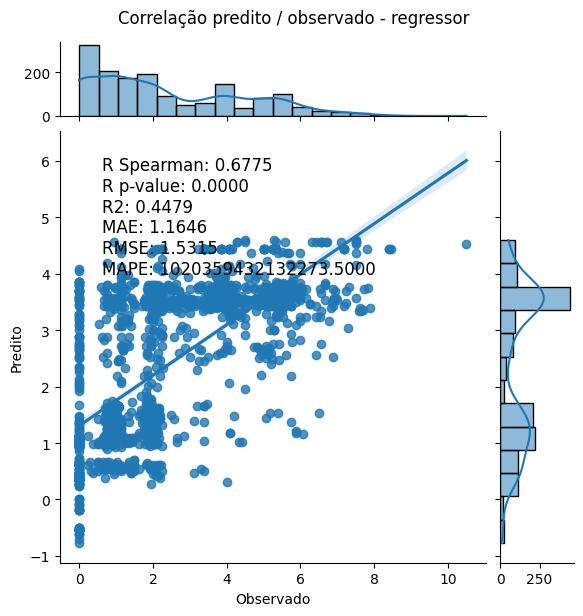

Iniciando o Grid Search com Cross Validation...


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 1
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unknown
19. cat__s

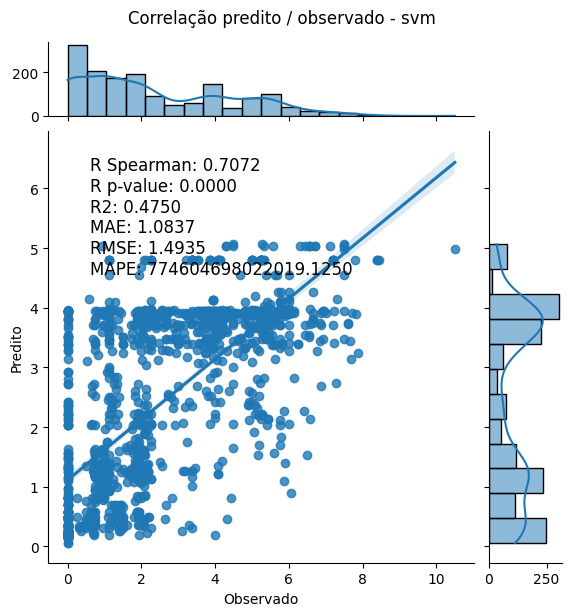

Iniciando o Grid Search com Cross Validation...


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    19
Total de variáveis selecionadas no modelo:    19

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella aerogenes
6. cat__Species_Klebsiella pneumoniae
7. cat__Species_Klebsiella quasipneumoniae
8. cat__Species_Outras
9. cat__Species_Proteus mirabilis
10. cat__Species_Serratia marcescens
11. cat__source_type_Body Fluid
12. cat__source_type_CNS
13. cat__source_type_Gastrointestinal
14. cat__source_type_Medical Device
15. cat__source_type_Other
16. cat__source_type_Respiratory
17. cat__source_type_Skin & Soft Tissue
18. cat__source_type_Unkno

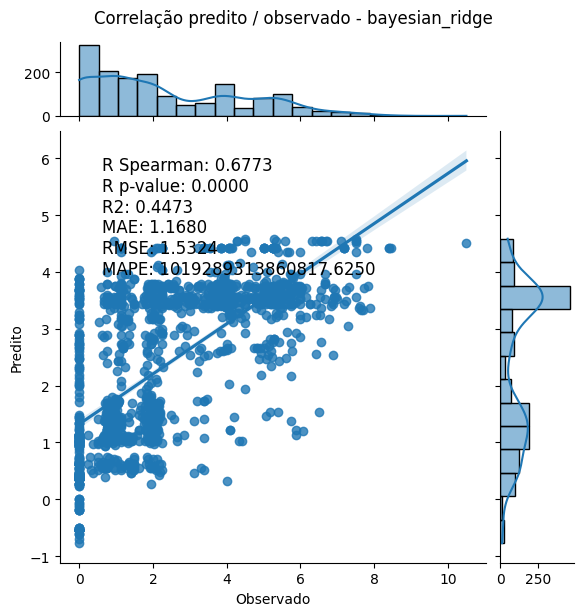

Iniciando o Grid Search com Cross Validation...


2026-10-25 09:14:53.724149: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
2026-10-25 09:14:53.729322: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
2026-10-25 09:14:53.762857: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
2026-10-25 09:14:53.765292: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/home/lusa/miniconda3/envs/ml_isolados/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.01
nn__optimizer -> Adam
nn__epochs -> 100
nn__batch_size -> 32
nn__activation2 -> softmax
nn__activation1 -> relu
feature_selection__k -> all
Total de variáveis originais pré-processadas: 19
Total de variáveis após VarianceThreshold:    16
Total de variáveis selecionadas no modelo:    16

--- Lista das Variáveis Selecionadas ---
1. num__Date
2. num__Date_na
3. cat__Species_Enterobacter hormaechei
4. cat__Species_Escherichia coli
5. cat__Species_Klebsiella pneumoniae
6. cat__Species_Klebsiella quasipneumoniae
7. cat__Species_Outras
8. cat__Species_Serratia marcescens
9. cat__source_type_CNS
10. cat__source_type_Gastrointestinal
11. cat__source_type_Medical Device
12. cat__source_type_Other
13. cat__source_type_Respiratory
14. cat__source_type_Skin & Soft Tissue
15. cat__source_type_Unknown
16. cat__source_type_Urinary

--- Status de Cada Atribut

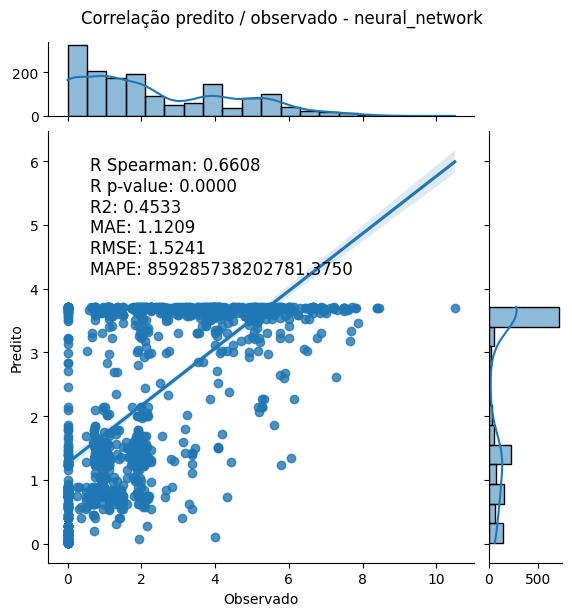

In [5]:
MODELOS = {"regressor": "Multiple Linear Regression", "svm": "Support Vector Machine",
           "bayesian_ridge": "Bayesian Ridge", "neural_network": "Neural Network"}

regressor = Regression(df=dados["treino"], target=Y)
for modelo in MODELOS:
    # rede neural: busca aleatória com 5 sorteios e 4 processos (cada um carrega o TensorFlow)
    extra = {"n_iter_search": 5, "n_jobs": 4} if modelo == "neural_network" else {}
    regressor.regress(modelo=modelo, **extra)

## 3. Métricas no treino, na validação e no teste

Validação e teste: `predict` do modelo ajustado no treino (hiperparâmetros congelados).

- **Spearman**: o modelo ordena bem os genomas por risco?
- **R²**: fração da variância do alvo explicada.
- **MAE / RMSE**: erro médio na unidade do `risco_idx` (RMSE pune mais os erros grandes).
- **MAE/DP**: MAE ÷ desvio-padrão do observado. O MAPE fica de fora: ~20% dos genomas têm
  `risco_idx` = 0.

In [ ]:
predicoes = {m: {c: np.ravel(regressor.modelos_[m].predict(df[regressor.X.columns])) for c, df in dados.items()}
             for m in MODELOS}


def metricas(y, pred):
    return {"spearman": spearmanr(y, pred)[0], 
            "r2": r2_score(y, pred), "mae": mean_absolute_error(y, pred),
            "rmse": np.sqrt(mean_squared_error(y, pred)), 
            "mae_dp": mean_absolute_error(y, pred) / y.std()}


metricas_regr = pd.DataFrame([{"modelo": MODELOS[m], "conjunto": c, **metricas(dados[c][Y], predicoes[m][c])}
                              for m in MODELOS for c in CONJUNTOS])
metricas_regr.set_index(["modelo", "conjunto"]).round(3)

spearman     r2    mae   rmse  mae_dp
modelo                     conjunto                                        
Multiple Linear Regression treino        0.678  0.448  1.165  1.531   0.565
                           validação     0.664  0.444  1.194  1.551   0.573
                           teste         0.705  0.473  1.209  1.548   0.566
Support Vector Machine     treino        0.707  0.475  1.084  1.493   0.526
                           validação     0.684  0.467  1.118  1.519   0.537
                           teste         0.711  0.488  1.142  1.526   0.535
Bayesian Ridge             treino        0.677  0.447  1.168  1.532   0.566
                           validação     0.667  0.445  1.198  1.550   0.575
                           teste         0.709  0.474  1.212  1.546   0.568
Neural Network             treino        0.661  0.453  1.121  1.524   0.544
                           validação     0.653  0.414  1.185  1.593   0.569
                           teste         0.700  0.441  1.206  1.594   0.565

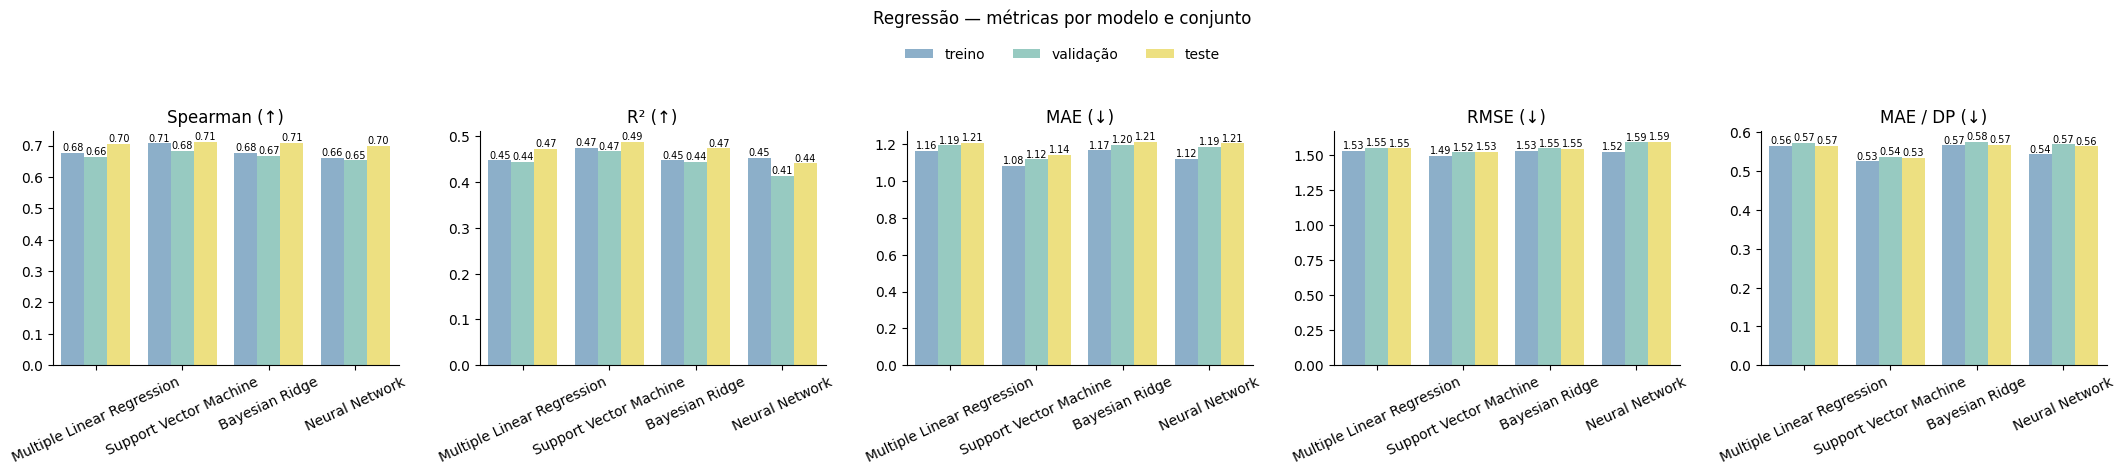

In [7]:
METRICAS_REGR = {"spearman": "Spearman (↑)", "r2": "R² (↑)", "mae": "MAE (↓)", "rmse": "RMSE (↓)",
                 "mae_dp": "MAE / DP (↓)"}
grafico_metricas(metricas_regr, METRICAS_REGR, "Regressão — métricas por modelo e conjunto")
plt.show()

## 4. As previsões se mantêm em dados novos? (treino × teste)

Comparam as **previsões** no treino com as previsões no teste (o valor real não entra): mesma
distribuição (KS), média (t de Welch), mediana (Mann-Whitney) e variância (Levene)?
p > 0,05 = não há evidência de diferença.

In [8]:
linhas = []
for m, nome in MODELOS.items():
    a, b = predicoes[m]["treino"], predicoes[m]["teste"]
    linhas.append({"modelo": nome, "KS_p": ks_2samp(a, b)[1], "t_Welch_p": ttest_ind(a, b, equal_var=False)[1],
                   "Mann_Whitney_p": mannwhitneyu(a, b)[1], "Levene_p": levene(a, b)[1]})
pd.DataFrame(linhas).set_index("modelo").round(3)

,KS_p,t_Welch_p,Mann_Whitney_p,Levene_p
modelo,,,,
Multiple Linear Regression,0.955,0.966,0.985,0.488
Support Vector Machine,0.995,0.766,0.816,0.612
Bayesian Ridge,0.940,0.974,0.946,0.504
Neural Network,0.962,0.864,0.948,0.957


## Exportação para o app

`train_resultados_regr` e `test_resultados_regr` (contexto, alvo e previsão de cada modelo),
`regr_hiperparametros.json` e `metricas_regr.csv` (gráfico de métricas).

In [9]:
from joblib import dump

pasta_app = RAIZ / "app/data"
tr_app, te_app = dados["treino"].copy(), dados["teste"].copy()
for m, nome in MODELOS.items():
    tr_app[nome] = predicoes[m]["treino"]
    te_app[nome] = predicoes[m]["teste"]
dump(tr_app, pasta_app / "train_resultados_regr")
dump(te_app, pasta_app / "test_resultados_regr")
metricas_regr.round(4).to_csv(pasta_app / "df_resultados/metricas_regr.csv", index=False)

hiper = {}
for m, nome in MODELOS.items():
    busca = regressor.modelos_[m]
    pipe = busca.best_estimator_
    hiper[nome] = {
        "modelo": m,
        "best_params": busca.best_params_,
        "n_originais": len(pipe["preprocessor"].get_feature_names_out()),
        "n_apos_variancia": int(pipe["var_threshold"].get_support().sum()),
        "n_selecionadas": int(pipe["feature_selection"].get_support().sum()),
    }
(pasta_app / "df_resultados/regr_hiperparametros.json").write_text(json.dumps(hiper, indent=2, default=str))
hiper

{'Multiple Linear Regression': {'modelo': 'regressor',
  'best_params': {'feature_selection__k': 'all',
   'regressor__fit_intercept': True,
   'regressor__positive': False,
   'var_threshold__threshold': 0.0001},
  'n_originais': 19,
  'n_apos_variancia': 19,
  'n_selecionadas': 19},
 'Support Vector Machine': {'modelo': 'svm',
  'best_params': {'feature_selection__k': 'all',
   'svm__C': 1,
   'svm__epsilon': 0.2,
   'svm__kernel': 'rbf',
   'var_threshold__threshold': 0.0001},
  'n_originais': 19,
  'n_apos_variancia': 19,
  'n_selecionadas': 19},
 'Bayesian Ridge': {'modelo': 'bayesian_ridge',
  'best_params': {'feature_selection__k': 'all',
   'nb__alpha_1': 0.0001,
   'nb__lambda_1': 1e-06,
   'nb__max_iter': 100,
   'var_threshold__threshold': 0.0001},
  'n_originais': 19,
  'n_apos_variancia': 19,
  'n_selecionadas': 19},
 'Neural Network': {'modelo': 'neural_network',
  'best_params': {'var_threshold__threshold': 0.01,
   'nn__optimizer': 'Adam',
   'nn__epochs': 100,
   'nn__